# Bab 8 – Tree-Based Algorithms and Ensemble Methods

## Ringkasan Bab
Model berbasis pohon membuat keputusan lewat serangkaian aturan "jika-maka". Satu pohon mudah dipahami tetapi gampang overfitting,
sehingga digabungkan menjadi **ensemble**: **bagging / Random Forest** (banyak pohon dilatih paralel) dan **Gradient Boosting**
(pohon dilatih berurutan untuk memperbaiki kesalahan sebelumnya). Bab ini juga membahas penyetelan hyperparameter dan perbandingan metode ensemble.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, time
from sklearn.datasets import load_breast_cancer, load_wine, make_moons
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import (RandomForestClassifier, BaggingClassifier, AdaBoostClassifier,
                              GradientBoostingClassifier, HistGradientBoostingClassifier, ExtraTreesClassifier)
from sklearn.model_selection import train_test_split, cross_val_score, RandomizedSearchCV, GridSearchCV
from sklearn.metrics import classification_report, accuracy_score
from scipy.stats import randint, uniform
X, y = load_breast_cancer(return_X_y=True, as_frame=True)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.25, stratify=y, random_state=42)

## 1. Pengantar Decision Tree
Pohon membagi data secara rekursif dengan memilih fitur dan ambang yang paling mengurangi **impurity** di node anak.
* **Gini:** 1 − Σ p_k²
* **Entropy:** −Σ p_k log₂ p_k
* **Information gain** = impurity induk − rata-rata berbobot impurity anak.

Kelebihan: tidak perlu scaling, bisa menangani fitur campuran, mudah dijelaskan. Kekurangan: pohon yang dalam menghafal data (varians tinggi).
Pengendali kompleksitas: `max_depth`, `min_samples_split`, `min_samples_leaf`, `ccp_alpha` (pruning).

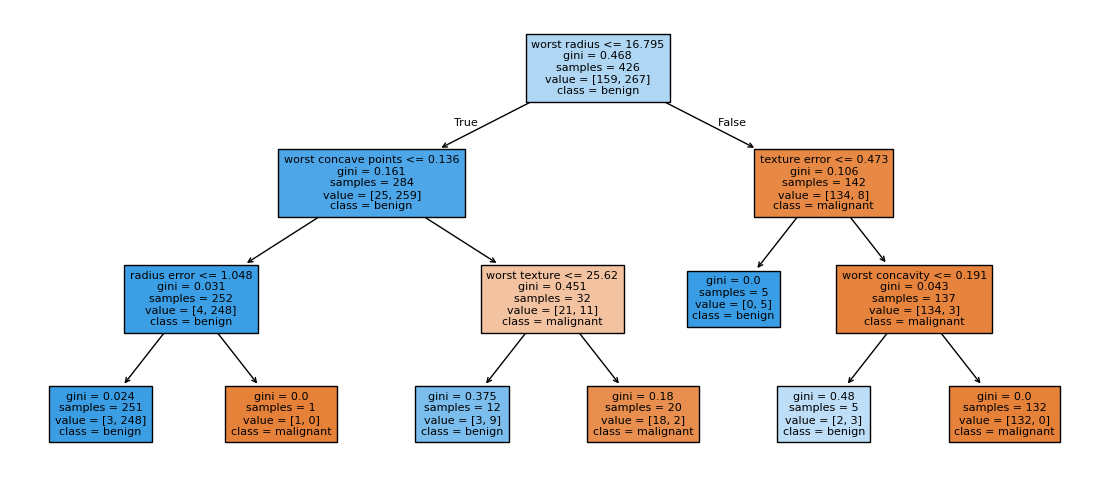

|--- worst radius <= 16.80
|   |--- worst concave points <= 0.14
|   |   |--- radius error <= 1.05
|   |   |   |--- class: 1
|   |   |--- radius error >  1.05
|   |   |   |--- class: 0
|   |--- worst concave points >  0.14
|   |   |--- worst texture <= 25.62
|   |   |   |--- class: 1
|   |   |--- worst texture >  25.62
|   |   |   |--- class: 0
|--- worst radius >  16.80
|   |--- texture error <= 0.47
|   |   |--- class: 1
|   |--- texture error >  0.47
|   |   |--- worst concavity <= 0.19
|   |   |   |--- class: 1
|   |   |--- worst concavity >  0.19
|   |   |   |--- class: 0



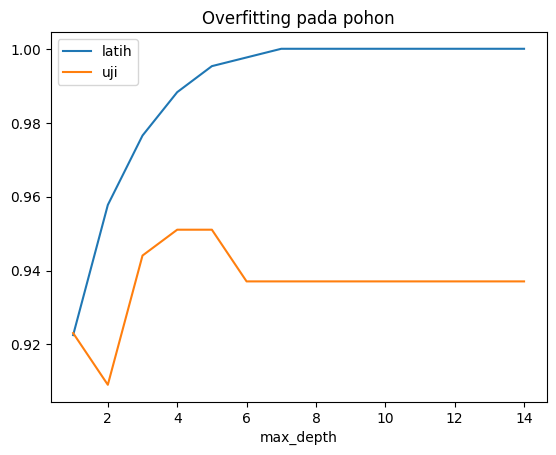

In [2]:
tree = DecisionTreeClassifier(max_depth=3, random_state=0).fit(Xtr, ytr)
plt.figure(figsize=(14, 6)); plot_tree(tree, feature_names=X.columns, class_names=["malignant", "benign"], filled=True, fontsize=8); plt.show()
print(export_text(tree, feature_names=list(X.columns))[:600])
depths = range(1, 15)
tr = [DecisionTreeClassifier(max_depth=d, random_state=0).fit(Xtr, ytr).score(Xtr, ytr) for d in depths]
te = [DecisionTreeClassifier(max_depth=d, random_state=0).fit(Xtr, ytr).score(Xte, yte) for d in depths]
plt.plot(depths, tr, label="latih"); plt.plot(depths, te, label="uji"); plt.legend(); plt.xlabel("max_depth"); plt.title("Overfitting pada pohon"); plt.show()

## 2. Random Forest dan Bagging
**Bagging** (bootstrap aggregating) melatih banyak model pada sampel bootstrap (pengambilan acak dengan pengembalian), lalu menggabungkan
hasilnya (voting atau rata-rata). Ini menurunkan **varians**. **Random Forest** menambah satu trik: setiap split hanya mempertimbangkan
subset fitur acak (`max_features`), sehingga pohon-pohonnya lebih beragam. Sampel yang tidak terpakai (*out-of-bag*) bisa dipakai sebagai
validasi gratis lewat `oob_score=True`.

Akurasi uji RF: 0.958 | OOB score: 0.958


Akurasi uji Bagging: 0.944


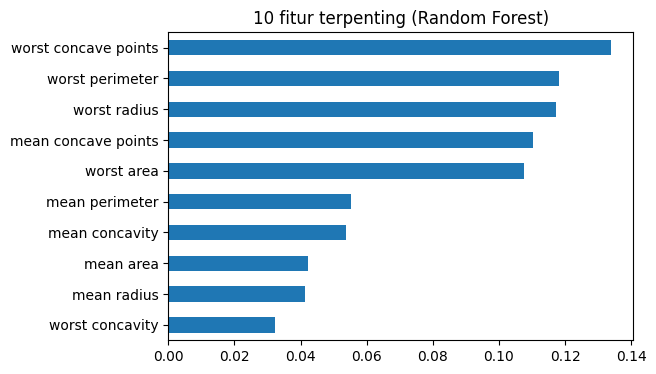

In [3]:
rf = RandomForestClassifier(n_estimators=300, oob_score=True, random_state=0, n_jobs=-1).fit(Xtr, ytr)
print("Akurasi uji RF:", round(rf.score(Xte, yte), 3), "| OOB score:", round(rf.oob_score_, 3))
bag = BaggingClassifier(DecisionTreeClassifier(), n_estimators=100, random_state=0, n_jobs=-1).fit(Xtr, ytr)
print("Akurasi uji Bagging:", round(bag.score(Xte, yte), 3))
imp = pd.Series(rf.feature_importances_, X.columns).sort_values().tail(10)
imp.plot.barh(figsize=(6, 4), title="10 fitur terpenting (Random Forest)"); plt.show()

## 3. Gradient Boosting
**Boosting** melatih model lemah (pohon dangkal) secara berurutan; setiap pohon baru memperbaiki kesalahan gabungan pohon sebelumnya.
Pada gradient boosting, pohon baru mempelajari **gradien negatif dari loss** (residual): F_m(x) = F_{m−1}(x) + η · h_m(x),
dengan η adalah `learning_rate`. Ini menurunkan **bias**, tetapi bisa overfitting jika terlalu banyak pohon.
Variannya: `GradientBoosting*`, `HistGradientBoosting*` (jauh lebih cepat, mendukung NaN), dan `AdaBoost` (membobot ulang sampel yang salah).

Akurasi uji GB: 0.958


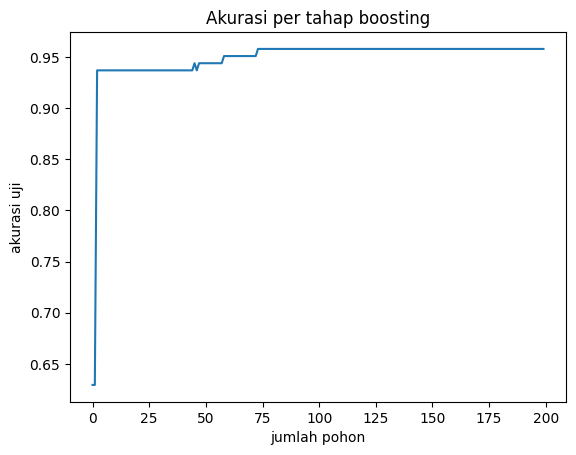

In [4]:
gb = GradientBoostingClassifier(n_estimators=200, learning_rate=.1, max_depth=3, random_state=0).fit(Xtr, ytr)
print("Akurasi uji GB:", round(gb.score(Xte, yte), 3))
stage = [accuracy_score(yte, p) for p in gb.staged_predict(Xte)]
plt.plot(stage); plt.xlabel("jumlah pohon"); plt.ylabel("akurasi uji"); plt.title("Akurasi per tahap boosting"); plt.show()

## 4. Menyetel Hyperparameter Pohon dan Ensemble
| Model | Hyperparameter penting |
|---|---|
| Decision Tree | `max_depth`, `min_samples_leaf`, `ccp_alpha` |
| Random Forest | `n_estimators`, `max_features`, `max_depth`, `min_samples_leaf` |
| Gradient Boosting | `n_estimators`, `learning_rate` (kecil + banyak pohon), `max_depth`, `subsample` |

`RandomizedSearchCV` lebih hemat waktu daripada grid ketika ruang pencariannya besar.

In [5]:
rs = RandomizedSearchCV(RandomForestClassifier(random_state=0, n_jobs=-1),
        {"n_estimators": randint(100, 500), "max_depth": [None, 4, 8, 12], "max_features": ["sqrt", "log2", 0.5],
         "min_samples_leaf": randint(1, 10)}, n_iter=20, cv=5, random_state=0, n_jobs=-1).fit(Xtr, ytr)
print("Terbaik:", rs.best_params_); print("CV:", round(rs.best_score_, 3), "| uji:", round(rs.score(Xte, yte), 3))

Terbaik: {'max_depth': None, 'max_features': 'log2', 'min_samples_leaf': 1, 'n_estimators': 423}
CV: 0.962 | uji: 0.958


## 5. Membandingkan Metode Ensemble
Rangkuman: **bagging/RF** menurunkan varians dan tahan terhadap overfitting; **boosting** menurunkan bias dan sering paling akurat,
tetapi lebih sensitif terhadap noise dan hyperparameter.

In [6]:
models = {"Decision Tree": DecisionTreeClassifier(random_state=0), "Random Forest": RandomForestClassifier(200, random_state=0, n_jobs=-1),
          "Extra Trees": ExtraTreesClassifier(200, random_state=0, n_jobs=-1), "AdaBoost": AdaBoostClassifier(random_state=0),
          "Gradient Boosting": GradientBoostingClassifier(random_state=0), "HistGradientBoosting": HistGradientBoostingClassifier(random_state=0)}
rows = []
for n, m in models.items():
    t = time.time(); s = cross_val_score(m, X, y, cv=5); rows.append({"model": n, "akurasi CV": round(s.mean(), 3), "std": round(s.std(), 3), "waktu (dtk)": round(time.time()-t, 2)})
pd.DataFrame(rows).sort_values("akurasi CV", ascending=False)

,model,akurasi CV,std,waktu (dtk)
5,HistGradientBoosting,0.967,0.012,0.83
3,AdaBoost,0.967,0.015,0.74
2,Extra Trees,0.965,0.017,1.12
4,Gradient Boosting,0.963,0.021,1.81
1,Random Forest,0.960,0.019,1.77
0,Decision Tree,0.917,0.016,0.05


## 6. Latihan Praktik

### Latihan 1 – Membangun dan Mengevaluasi Decision Tree

In [7]:
dt = DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, random_state=0).fit(Xtr, ytr)
print(classification_report(yte, dt.predict(Xte), target_names=["malignant", "benign"]))

              precision    recall  f1-score   support

   malignant       0.91      0.91      0.91        53
      benign       0.94      0.94      0.94        90

    accuracy                           0.93       143
   macro avg       0.93      0.93      0.93       143
weighted avg       0.93      0.93      0.93       143



### Latihan 2 – Menyetel Random Forest dengan Randomized Search
Sudah dikerjakan pada bagian 4. Di sini kita bandingkan model default dan model hasil penyetelan.

In [8]:
default = RandomForestClassifier(random_state=0).fit(Xtr, ytr)
print("RF default:", round(default.score(Xte, yte), 3), "| RF hasil penyetelan:", round(rs.best_estimator_.score(Xte, yte), 3))

RF default: 0.958 | RF hasil penyetelan: 0.958


### Latihan 3 – Membandingkan Gradient Boosting
Pengaruh `learning_rate` dan `n_estimators` terhadap akurasi.

In [9]:
rows = []
for lr_ in [0.01, 0.1, 0.5]:
    for n in [50, 200]:
        m = GradientBoostingClassifier(learning_rate=lr_, n_estimators=n, random_state=0).fit(Xtr, ytr)
        rows.append({"learning_rate": lr_, "n_estimators": n, "akurasi uji": round(m.score(Xte, yte), 3)})
pd.DataFrame(rows).pivot(index="learning_rate", columns="n_estimators", values="akurasi uji")

n_estimators,50,200
learning_rate,,
0.01,0.937,0.937
0.10,0.944,0.958
0.50,0.951,0.965


**Kesimpulan:** satu pohon mudah dipahami tetapi tidak stabil. Random Forest adalah baseline yang kuat dengan sedikit penyetelan,
dan gradient boosting biasanya memberi akurasi tertinggi pada data tabular bila disetel dengan baik.